
# 03 - Closed-set Baselines and Model Selection

**Input:** `clap_embeddings.npz` (512-dimensional frozen CLAP) and `handcrafted_features.csv` (36 acoustic features). Both represent the same 3,000 audio clips with prompt-grouped splits.

**Goal:** Compare Logistic Regression, SVM and k-NN on both representations, include a DummyClassifier, select the winner using validation Macro F1, and report its final test metrics once. Detailed confusion matrices, per-class analysis and example mistakes belong to `04-error-analysis.ipynb`.

**Outputs:** `results/baseline_comparison.csv`, `results/baseline_test_metrics.json`, `results/clap_logreg_predictions.csv`.

In [1]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
PROJECT_ROOT


WindowsPath('d:/UCU/33333333333333333/AI/AI-vs-Original-Music-Classification')


## Loading CLAP Embeddings

The dataset contains 3,000 audio tracks from 5 music generators, with each track represented by a 512-dimensional CLAP embedding.

The file also includes track IDs, generator labels, and predefined data splits.


In [2]:
import numpy as np
import pandas as pd
from IPython.display import display
from ai_music_origin.config import load_config
from ai_music_origin.models import build_logistic_regression, build_svm, build_knn, build_baseline
from ai_music_origin.evaluate import compute_metrics

In [6]:
with np.load(PROJECT_ROOT / 'data/interim/clap_embeddings.npz', allow_pickle=True) as saved:
    embeddings = saved['embeddings']
    track_ids = saved['track_ids'].astype(str)
    generators = saved['generators'].astype(str)
    splits = saved['splits'].astype(str)
metadata = pd.DataFrame({'track_id': track_ids, 'generator': generators, 'split': splits})
class_names = sorted(np.unique(generators).tolist())
config = load_config(PROJECT_ROOT / 'config/default.yaml')
print("Loaded CLAP embeddings")

Loaded CLAP embeddings


In [5]:
train_mask, val_mask, test_mask = (splits == s for s in ('train','validation','test'))
X_train, X_val, X_test = embeddings[train_mask], embeddings[val_mask], embeddings[test_mask]
y_train, y_val, y_test = generators[train_mask], generators[val_mask], generators[test_mask]
print("Loaded predefined splits.")

Loaded predefined splits.



## 3. Logistic Regression

Logistic Regression is the first classification model used in the experiment.

The model is trained on CLAP embeddings and evaluated on the validation set.

StandardScaler is applied inside the pipeline to standardize the input features.


In [5]:

from ai_music_origin.config import load_config
from ai_music_origin.models import build_logistic_regression
from ai_music_origin.evaluate import compute_metrics

# Load model configuration
config = load_config(PROJECT_ROOT / "config/default.yaml")

# Create the model
lr_model = build_logistic_regression(config)

# Train only on training data
lr_model.fit(X_train, y_train)

# Predict on validation data
y_val_pred = lr_model.predict(X_val)

# Calculate evaluation metrics
lr_metrics = compute_metrics(
    y_val,
    y_val_pred,
    labels=sorted(np.unique(generators).tolist())
)

print("Logistic Regression — Validation Results")

for metric, value in lr_metrics.items():
    if metric != "confusion_matrix":
        print(f"{metric}: {value:.4f}")


Logistic Regression — Validation Results
accuracy: 0.8711
balanced_accuracy: 0.8711
macro_f1: 0.8713
macro_precision: 0.8732
macro_recall: 0.8711



## 4. SVM and k-NN

Two additional classifiers are trained on CLAP embeddings:

- SVM uses decision boundaries to separate different generator classes.
- k-NN predicts the generator based on the nearest training samples.

Both models use StandardScaler and the same training and validation sets as Logistic Regression.


In [6]:

from ai_music_origin.models import build_svm, build_knn

# Create SVM and k-NN models
models = {
    "SVM": build_svm(config),
    "k-NN": build_knn(config),
}

# Store model results
model_results = {
    "Logistic Regression": lr_metrics
}

trained_models = {
    "Logistic Regression": lr_model
}

# Train and evaluate on validation data
for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    metrics = compute_metrics(
        y_val,
        y_pred,
        labels=sorted(np.unique(generators).tolist())
    )

    model_results[name] = metrics
    trained_models[name] = model

    print(f"{name} — Validation Results")
    for metric, value in metrics.items():
        if metric != "confusion_matrix":
            print(f"{metric}: {value:.4f}")



Training SVM...
SVM — Validation Results
accuracy: 0.8689
balanced_accuracy: 0.8689
macro_f1: 0.8685
macro_precision: 0.8696
macro_recall: 0.8689

Training k-NN...
k-NN — Validation Results
accuracy: 0.7911
balanced_accuracy: 0.7911
macro_f1: 0.7921
macro_precision: 0.8026
macro_recall: 0.7911


C:\Users\Sofiia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Sofiia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^


## 5. CLAP Model Comparison

The validation results of all three classifiers are compared.

Macro F1 is used as the main evaluation metric because it gives equal importance to each generator class.

The comparison helps identify which classifier performs best with CLAP embeddings.


In [7]:
comparison = pd.DataFrame({
    name: {
        metric: value
        for metric, value in metrics.items()
        if metric != "confusion_matrix"
    }
    for name, metrics in model_results.items()
}).T

comparison = comparison.sort_values(
    by="macro_f1",
    ascending=False
)

display(comparison.round(4))


,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall
Logistic Regression,0.8711,0.8711,0.8713,0.8732,0.8711
SVM,0.8689,0.8689,0.8685,0.8696,0.8689
k-NN,0.7911,0.7911,0.7921,0.8026,0.7911



## 6. Confusion Matrices

Confusion matrices show how many samples from each generator are classified correctly or incorrectly.

Rows represent the true generator, while columns represent the predicted generator.

This helps identify which music generators are most difficult to distinguish.


In [8]:
from ai_music_origin.evaluate import plot_confusion_matrix

# Class names in a consistent order
class_names = sorted(np.unique(generators).tolist())

# Save confusion matrices for all models
for name, metrics in model_results.items():
    output_path = (
        PROJECT_ROOT
        / "results"
        / "figures"
        / f"{name.lower().replace(' ', '_')}_confusion_matrix.png"
    )

    plot_confusion_matrix(
        cm=metrics["confusion_matrix"],
        class_names=class_names,
        output_path=output_path
    )

    print(f"Saved: {output_path.name}")


Saved: logistic_regression_confusion_matrix.png
Saved: svm_confusion_matrix.png
Saved: k-nn_confusion_matrix.png


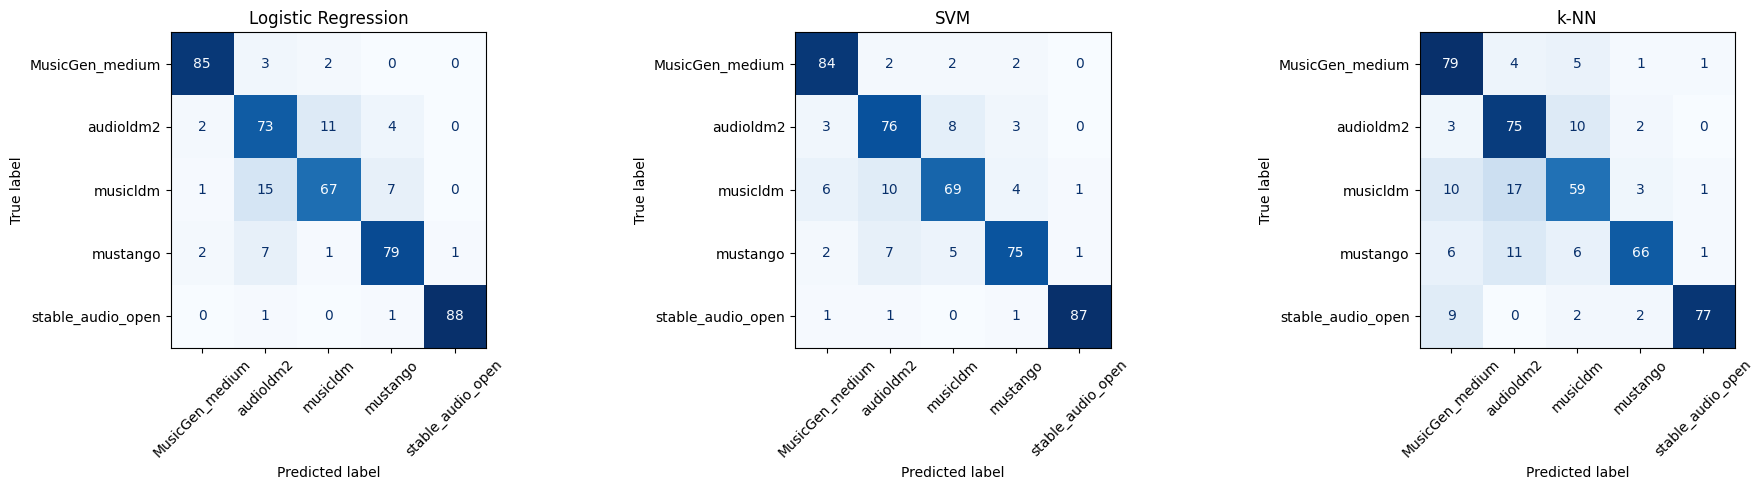

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (name, metrics) in zip(
    axes, model_results.items()
):
    ConfusionMatrixDisplay(
        confusion_matrix=np.array(metrics["confusion_matrix"]),
        display_labels=class_names
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [10]:
# Save CLAP embeddings baseline results
results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

comparison_to_save = comparison.copy()
comparison_to_save.index.name = "model"
comparison_to_save.insert(0, "features", "CLAP embeddings")

output_path = results_dir / "clap_baseline_metrics.csv"

comparison_to_save.to_csv(output_path)

print(f"Results saved to: {output_path}")


Results saved to: c:\Users\Sofiia\UCU\year3\semester1\AI\AI-vs-Original-Music-Classification\results\clap_baseline_metrics.csv



## 7. Handcrafted Features

The handcrafted dataset contains 36 acoustic features, including RMS, zero-crossing rate, spectral features, and MFCCs.

Before training, the dataset is checked to confirm that all 3,000 samples match the CLAP dataset and use the same train/validation/test split.

Each sample is matched using its track ID and generator label.


In [11]:
handcrafted_path = PROJECT_ROOT / "data/interim/handcrafted_features.csv"

handcrafted_df = pd.read_csv(handcrafted_path)

print("Shape:", handcrafted_df.shape)
print("\nColumns:", handcrafted_df.columns.tolist())
display(handcrafted_df.head())

Shape: (3000, 39)

Columns: ['rms_mean', 'rms_std', 'zero_mean', 'zero_std', 'spectral_centroid_mean', 'spectral_centroid_std', 'spectral_bandwidth_mean', 'spectral_bandwidth_std', 'spectral_rolloff_mean', 'spectral_rolloff_std', 'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std', 'track_id', 'generator', 'split']


,rms_mean,rms_std,zero_mean,zero_std,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,...,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,track_id,generator,split
0,0.050200,0.042277,0.112701,0.097801,1619.412474,1171.219198,1436.768010,799.679361,3195.537141,2252.611350,...,8.675249,-3.814042,6.888627,-2.643897,6.289780,-5.682254,5.927766,-Dtir74TiUM,MusicGen_medium,train
1,0.163195,0.052746,0.115033,0.040164,1968.384681,345.833596,1971.522850,162.513330,4294.304113,663.787604,...,6.288491,4.218235,6.675289,3.523986,6.923249,-0.515269,7.300800,-FlvaZQOr2I,MusicGen_medium,validation
2,0.060365,0.013300,0.085967,0.020033,1108.734151,234.334299,1187.491204,153.979208,2335.238618,496.713482,...,9.814955,5.130897,14.344102,4.662229,12.729595,1.480072,8.129430,-IZbvEO9wzU,MusicGen_medium,validation
3,0.058199,0.036733,0.083287,0.053009,1233.032207,507.532216,1414.098807,341.359129,2812.999201,999.320068,...,6.921867,-1.004193,6.488622,-8.165395,7.488440,-11.879418,6.576658,-M-6VinyMiY,MusicGen_medium,train
4,0.237368,0.039773,0.032905,0.006067,365.494246,47.639152,404.791364,115.103523,560.403355,136.921993,...,5.070801,-6.841511,5.334469,-15.128489,7.255623,-17.778114,9.146493,-VclCul6FrI,MusicGen_medium,train


In [12]:
# Compare metadata between CLAP and handcrafted features

key_columns = ["track_id", "generator"]

clap_meta = metadata[
    ["track_id", "generator", "split"]
].copy()

handcrafted_meta = handcrafted_df[
    ["track_id", "generator", "split"]
].copy()

# Check unique (track_id, generator) combinations
assert not clap_meta.duplicated(key_columns).any()
assert not handcrafted_meta.duplicated(key_columns).any()

# Match tracks using BOTH track_id and generator
matched = clap_meta.merge(
    handcrafted_meta,
    on=key_columns,
    how="outer",
    suffixes=("_clap", "_handcrafted"),
    indicator=True,
    validate="one_to_one"
)

print("Matching status:")
print(matched["_merge"].value_counts())

assert (matched["_merge"] == "both").all(), (
    "Some tracks are missing from one of the datasets"
)

# Check that both datasets use exactly the same split
assert (
    matched["split_clap"] == matched["split_handcrafted"]
).all(), "Split mismatch between datasets"

print("\nAll 3000 tracks matched!")
print("Train/validation/test splits are identical!")


Matching status:
_merge
both          3000
left_only        0
right_only       0
Name: count, dtype: int64

All 3000 tracks matched!
Train/validation/test splits are identical!


In [13]:
# Select only acoustic features (exclude metadata)
feature_columns = [
    col for col in handcrafted_df.columns
    if col not in ["track_id", "generator", "split"]
]

print("Number of handcrafted features:", len(feature_columns))

# Use the existing predefined split
hc_train = handcrafted_df["split"] == "train"
hc_val = handcrafted_df["split"] == "validation"
hc_test = handcrafted_df["split"] == "test"

# Prepare feature matrices
X_train_hc = handcrafted_df.loc[hc_train, feature_columns]
X_val_hc = handcrafted_df.loc[hc_val, feature_columns]
X_test_hc = handcrafted_df.loc[hc_test, feature_columns]

# Prepare labels
y_train_hc = handcrafted_df.loc[hc_train, "generator"]
y_val_hc = handcrafted_df.loc[hc_val, "generator"]
y_test_hc = handcrafted_df.loc[hc_test, "generator"]

print("Train:", X_train_hc.shape)
print("Validation:", X_val_hc.shape)
print("Test:", X_test_hc.shape)

# Verify the data
assert len(feature_columns) == 36
assert X_train_hc.shape[0] == len(y_train_hc)
assert X_val_hc.shape[0] == len(y_val_hc)
assert X_test_hc.shape[0] == len(y_test_hc)

print("\nMissing values:", X_train_hc.isna().sum().sum()
      + X_val_hc.isna().sum().sum()
      + X_test_hc.isna().sum().sum())


Number of handcrafted features: 36
Train: (2100, 36)
Validation: (450, 36)
Test: (450, 36)

Missing values: 0



## 8. Handcrafted Model Training

Logistic Regression, SVM, and k-NN are trained using 36 handcrafted audio features.

The same model settings and predefined data split are used as in the CLAP experiments.

All three models are evaluated on the validation set using the same metrics.


In [14]:
from ai_music_origin.models import (
    build_logistic_regression,
    build_svm,
    build_knn,
)

# Create the same baseline classifiers as for CLAP
hc_models = {
    "Logistic Regression": build_logistic_regression(config),
    "SVM": build_svm(config),
    "k-NN": build_knn(config),
}

hc_results = {}
hc_trained_models = {}

class_names = sorted(np.unique(generators).tolist())

# Train and evaluate each model
for name, model in hc_models.items():
    print(f"\nTraining {name} on handcrafted features...")

    model.fit(X_train_hc, y_train_hc)

    y_pred = model.predict(X_val_hc)

    metrics = compute_metrics(
        y_val_hc,
        y_pred,
        labels=class_names
    )

    hc_results[name] = metrics
    hc_trained_models[name] = model

    print(f"{name} — Validation Results")

    for metric, value in metrics.items():
        if metric != "confusion_matrix":
            print(f"{metric}: {value:.4f}")



Training Logistic Regression on handcrafted features...
Logistic Regression — Validation Results
accuracy: 0.7689
balanced_accuracy: 0.7689
macro_f1: 0.7657
macro_precision: 0.7697
macro_recall: 0.7689

Training SVM on handcrafted features...
SVM — Validation Results
accuracy: 0.8222
balanced_accuracy: 0.8222
macro_f1: 0.8209
macro_precision: 0.8218
macro_recall: 0.8222

Training k-NN on handcrafted features...
k-NN — Validation Results
accuracy: 0.7178
balanced_accuracy: 0.7178
macro_f1: 0.7183
macro_precision: 0.7228
macro_recall: 0.7178



## 9. Final Model Comparison

The results of all six model and feature combinations are compared using validation metrics.

CLAP embeddings achieve better results than handcrafted features for all three classifiers.

Logistic Regression with CLAP embeddings has the highest validation Macro F1-score of 0.8713.


In [15]:
# Combine results from both feature representations

all_results = []

for feature_type, results in [
    ("CLAP embeddings", model_results),
    ("Handcrafted features", hc_results)
]:
    for model_name, metrics in results.items():
        all_results.append({
            "Features": feature_type,
            "Model": model_name,
            "Accuracy": metrics["accuracy"],
            "Balanced Accuracy": metrics["balanced_accuracy"],
            "Macro F1": metrics["macro_f1"],
            "Macro Precision": metrics["macro_precision"],
            "Macro Recall": metrics["macro_recall"],
        })

final_comparison = pd.DataFrame(all_results)

final_comparison = final_comparison.sort_values(
    by="Macro F1",
    ascending=False
)

display(final_comparison.round(4))


,Features,Model,Accuracy,Balanced Accuracy,Macro F1,Macro Precision,Macro Recall
0,CLAP embeddings,Logistic Regression,0.8711,0.8711,0.8713,0.8732,0.8711
1,CLAP embeddings,SVM,0.8689,0.8689,0.8685,0.8696,0.8689
4,Handcrafted features,SVM,0.8222,0.8222,0.8209,0.8218,0.8222
2,CLAP embeddings,k-NN,0.7911,0.7911,0.7921,0.8026,0.7911
3,Handcrafted features,Logistic Regression,0.7689,0.7689,0.7657,0.7697,0.7689
5,Handcrafted features,k-NN,0.7178,0.7178,0.7183,0.7228,0.7178



## 10. Majority-Class Baseline

DummyClassifier is used as a simple reference model.

It always predicts the most frequent class without learning from the audio features.

The dataset contains five balanced classes, so the expected accuracy is 20%.

This baseline helps show whether the trained classifiers perform better than a simple prediction strategy.


In [16]:
from ai_music_origin.models import build_baseline

# Create majority-class baseline
dummy_model = build_baseline()

# Train only on training data
dummy_model.fit(X_train, y_train)

# Evaluate on validation data
dummy_pred = dummy_model.predict(X_val)

dummy_metrics = compute_metrics(
    y_val,
    dummy_pred,
    labels=class_names
)

print("DummyClassifier — Validation Results")

for metric, value in dummy_metrics.items():
    if metric != "confusion_matrix":
        print(f"{metric}: {value:.4f}")


DummyClassifier — Validation Results
accuracy: 0.2000
balanced_accuracy: 0.2000
macro_f1: 0.0667
macro_precision: 0.0400
macro_recall: 0.2000



## 11. Final Test Evaluation

Logistic Regression with CLAP embeddings is selected based on the highest validation Macro F1-score.

The selected model is evaluated on the independent test set, which was not used for training or model selection.

The final test Macro F1-score is 0.8378.


In [17]:
# Final evaluation of the selected model

best_model_name = "Logistic Regression"
best_feature_type = "CLAP embeddings"

# Selected using validation Macro F1
best_model = trained_models[best_model_name]

# Evaluate on the untouched test set
y_test_pred = best_model.predict(X_test)

test_metrics = compute_metrics(
    y_test,
    y_test_pred,
    labels=class_names
)

print("Final Test Results")
print("Model:", best_model_name)
print("Features:", best_feature_type)

for metric, value in test_metrics.items():
    if metric != "confusion_matrix":
        print(f"{metric}: {value:.4f}")


Final Test Results


Model: Logistic Regression
Features: CLAP embeddings
accuracy: 0.8378
balanced_accuracy: 0.8378
macro_f1: 0.8378
macro_precision: 0.8380
macro_recall: 0.8378



## 12. Saving Results

The experiment results are saved in the `results/` directory.

The output includes:
- `baseline_comparison.csv` — validation results for all six model combinations.
- `baseline_test_metrics.json` — final test metrics of the selected model.
- `baseline_test_confusion_matrix.png` — confusion matrix for the final test.

These files make the results available for further analysis and comparison.


In [18]:
import json

results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Save comparison of all six model/feature combinations
comparison_path = results_dir / "baseline_comparison.csv"
final_comparison.to_csv(comparison_path, index=False)

# Save final test metrics
test_results = {
    "model": best_model_name,
    "features": best_feature_type,
    "validation_macro_f1": model_results[best_model_name]["macro_f1"],
    "test_metrics": test_metrics,
}

test_path = results_dir / "baseline_test_metrics.json"

with open(test_path, "w", encoding="utf-8") as f:
    json.dump(test_results, f, indent=4)

# Save test confusion matrix
from ai_music_origin.evaluate import plot_confusion_matrix

cm_path = results_dir / "figures" / "baseline_test_confusion_matrix.png"

plot_confusion_matrix(
    cm=test_metrics["confusion_matrix"],
    class_names=class_names,
    output_path=cm_path,
)

print("Saved:")
print(comparison_path)
print(test_path)
print(cm_path)


Saved:
c:\Users\Sofiia\UCU\year3\semester1\AI\AI-vs-Original-Music-Classification\results\baseline_comparison.csv
c:\Users\Sofiia\UCU\year3\semester1\AI\AI-vs-Original-Music-Classification\results\baseline_test_metrics.json
c:\Users\Sofiia\UCU\year3\semester1\AI\AI-vs-Original-Music-Classification\results\figures\baseline_test_confusion_matrix.png


## Conclusion

We tested three machine learning models: Logistic Regression, SVM, and k-NN. We used two types of audio features: handcrafted features (36 features) and CLAP embeddings (512 features).

We used the same train, validation, and test split (70%/15%/15%) for all models to make the comparison fair.

### Main Results

- CLAP embeddings gave better results than handcrafted features for all three models.
- **Logistic Regression with CLAP embeddings** was the best model, with a validation Macro F1-score of **0.8713**.
- For handcrafted features, **SVM** performed best, with a Macro F1-score of **0.8209**.
- k-NN had lower results than the other models.
- DummyClassifier had a Macro F1-score of only **0.0667**, showing that our models performed much better than a simple baseline.

### Final Test Results

We tested the best model, Logistic Regression with CLAP embeddings, on the test dataset.

- Accuracy: **0.8378**
- Balanced Accuracy: **0.8378**
- Macro F1: **0.8378**
- Macro Precision: **0.8380**
- Macro Recall: **0.8378**

The test results were slightly lower than the validation results, but the model still performed well on new data.

### Overall Conclusion

Our experiments showed that **CLAP embeddings work better than handcrafted features** for identifying which AI model generated a music track.

Logistic Regression gave the best overall results, even though it is a relatively simple model.